# 04 · Visuals: what the cascades look like
Reads the **gold** and **silver** tables written by notebook 03 and draws the six charts used in the slides, the dashboard and the README.

In [1]:
import os, subprocess
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pyspark.sql import SparkSession

RUN_ON = "gcp"        # "local" = laptop ; "gcp" = Dataproc cluster reading/writing Cloud Storage
BUCKET = "flightdelay-olivia-2026"   # bucket name only (not a secret); used when RUN_ON = "gcp"

if RUN_ON == "gcp":
    PROP      = f"gs://{BUCKET}/gold"                 # outputs of notebook 03
    FIG       = Path("/tmp/figures");  TABLES = Path("/tmp/tables")      # written on the cluster, then copied to the bucket
    FIG_DEST, TABLES_DEST = f"{PROP}/figures", f"{PROP}/tables"
else:
    PROJECT   = Path(os.path.expanduser("~/Desktop/ADSP32030_Scalable/Project"))
    PROP      = str(PROJECT/"data/propagation")
    FIG       = PROJECT/"figures";     TABLES = Path(PROP)/"tables"
    FIG_DEST = TABLES_DEST = None
FIG.mkdir(parents=True, exist_ok=True); TABLES.mkdir(parents=True, exist_ok=True)

builder = (SparkSession.builder.appName("flight-delay-visuals")
           .config("spark.sql.shuffle.partitions", "64").config("spark.sql.session.timeZone", "UTC"))
if RUN_ON == "local":
    builder = (builder.master("local[4]").config("spark.driver.memory", "6g")
               .config("spark.driver.bindAddress", "127.0.0.1").config("spark.driver.host", "127.0.0.1"))
else:
    # Dataproc defaults to an Iceberg catalog whose jar is not on this kernel's classpath; this job only needs plain Parquet
    builder = builder.config("spark.sql.defaultCatalog", "spark_catalog").config("spark.sql.extensions", "")
spark = builder.getOrCreate(); spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version, "| run on:", RUN_ON, "| reading:", PROP)

for name in ["cascades", "flight_chains", "flights_features", "summary_airport_hour"]:      # gold + silver tables from notebook 03
    spark.read.parquet(f"{PROP}/{name}").createOrReplaceTempView(name)
def q(sql):
    df = spark.sql(sql).toPandas()
    for c in df.columns:                      # Spark returns Decimal for some arithmetic: make those plain numbers
        if df[c].dtype == object:
            try: df[c] = pd.to_numeric(df[c])
            except (ValueError, TypeError): pass
    return df

NAVY, BLUE, LIGHT, GREY, RED = "#1F3A6E", "#4C78C8", "#A9BEE6", "#8A8F98", "#C8553D"
mpl.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110})
def save(fig, name):
    fig.savefig(FIG/f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 23:53:59 INFO SparkEnv: Registering MapOutputTracker
26/11/20 23:53:59 INFO SparkEnv: Registering BlockManagerMaster
26/11/20 23:53:59 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/11/20 23:54:00 INFO SparkEnv: Registering OutputCommitCoordinator


Spark 3.5.3 | run on: gcp | reading: gs://flightdelay-olivia-2026/gold


26/11/20 23:54:14 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


## 1 · Where cascades start: top airports (count and rate)

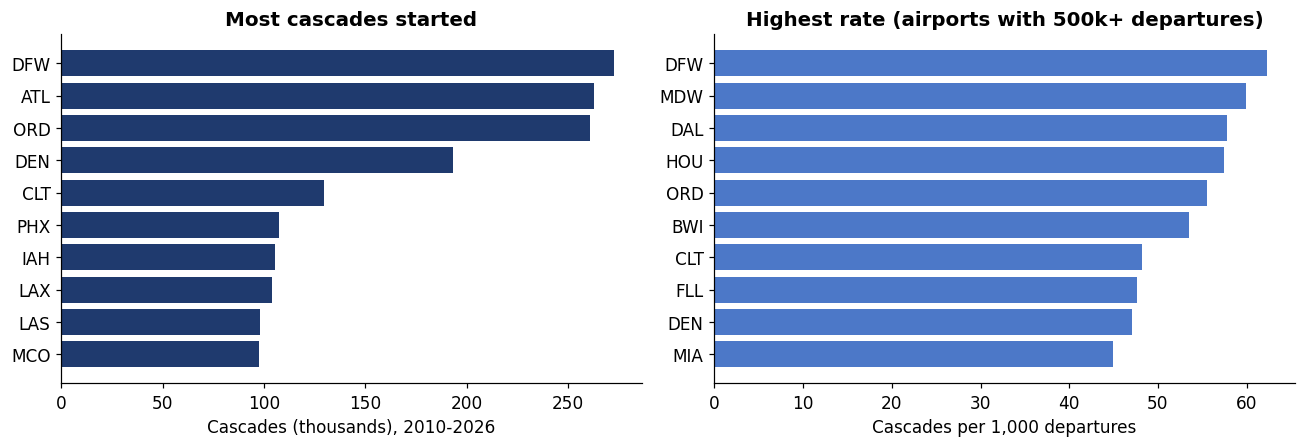

In [2]:
by_ap = q(f"""
WITH c AS (SELECT root_origin AS airport, count(*) AS cascades FROM cascades GROUP BY 1),
     d AS (SELECT Origin AS airport, count(*) AS departures FROM flight_chains GROUP BY 1)
SELECT c.airport, c.cascades, d.departures, 1000.0*c.cascades/d.departures AS per_1000
FROM c JOIN d USING (airport)""")
by_ap.to_csv(TABLES/"cascades_by_airport.csv", index=False)

top_n = by_ap.nlargest(10, "cascades").sort_values("cascades")
top_r = by_ap[by_ap.departures >= 500_000].nlargest(10, "per_1000").sort_values("per_1000")   # big airports only: small ones are noisy

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(top_n.airport, top_n.cascades/1000, color=NAVY)
ax[0].set_title("Most cascades started"); ax[0].set_xlabel("Cascades (thousands), 2010-2026")
ax[1].barh(top_r.airport, top_r.per_1000, color=BLUE)
ax[1].set_title("Highest rate (airports with 500k+ departures)"); ax[1].set_xlabel("Cascades per 1,000 departures")
fig.tight_layout(); save(fig, "01_top_airports")

## 2 · When: cascades by local hour of the root flight

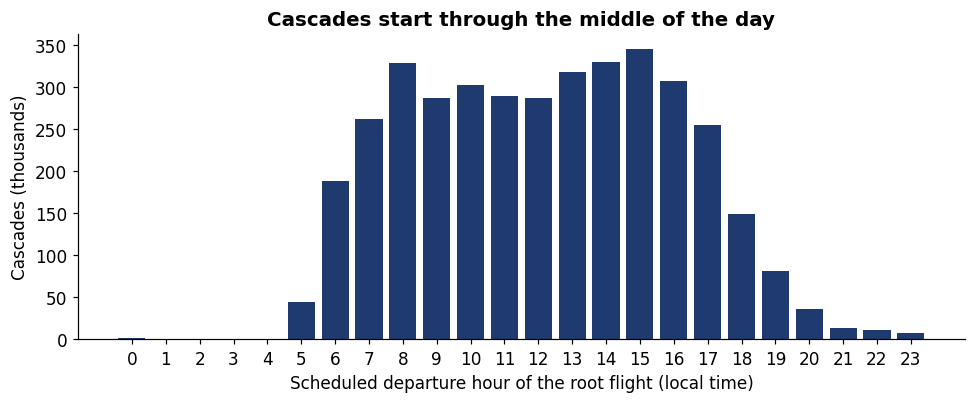

In [3]:
summ = q("SELECT * FROM summary_airport_hour")
by_hr = summ.groupby("local_hour", as_index=False).cascades.sum()
by_hr.to_csv(TABLES/"cascades_by_hour.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(by_hr.local_hour, by_hr.cascades/1000, color=NAVY)
ax.set_xticks(range(0, 24)); ax.set_xlabel("Scheduled departure hour of the root flight (local time)"); ax.set_ylabel("Cascades (thousands)")
ax.set_title("Cascades start through the middle of the day"); fig.tight_layout(); save(fig, "02_cascades_by_hour")

## 3 · Airport × hour heatmap (top 15 airports)

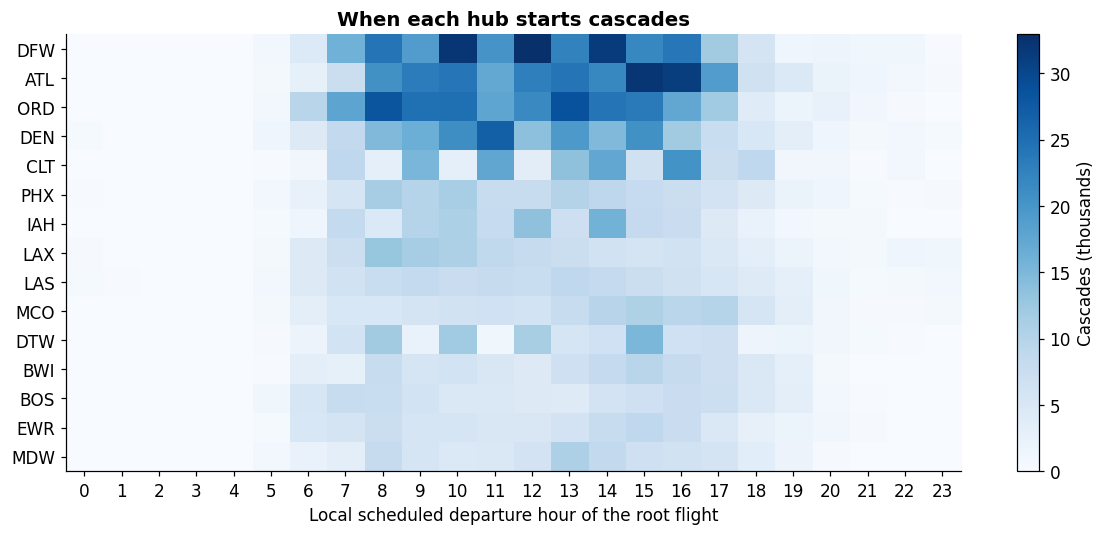

In [4]:
top15 = summ.groupby("airport").cascades.sum().nlargest(15).index
heat = (summ[summ.airport.isin(top15)].pivot_table(index="airport", columns="local_hour", values="cascades", fill_value=0)
        .reindex(top15).reindex(columns=range(24), fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(heat.values/1000, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index); ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_xlabel("Local scheduled departure hour of the root flight"); ax.set_title("When each hub starts cascades")
fig.colorbar(im, ax=ax, label="Cascades (thousands)"); fig.tight_layout(); save(fig, "03_airport_hour_heatmap")

## 4 · Over time: cascades per year

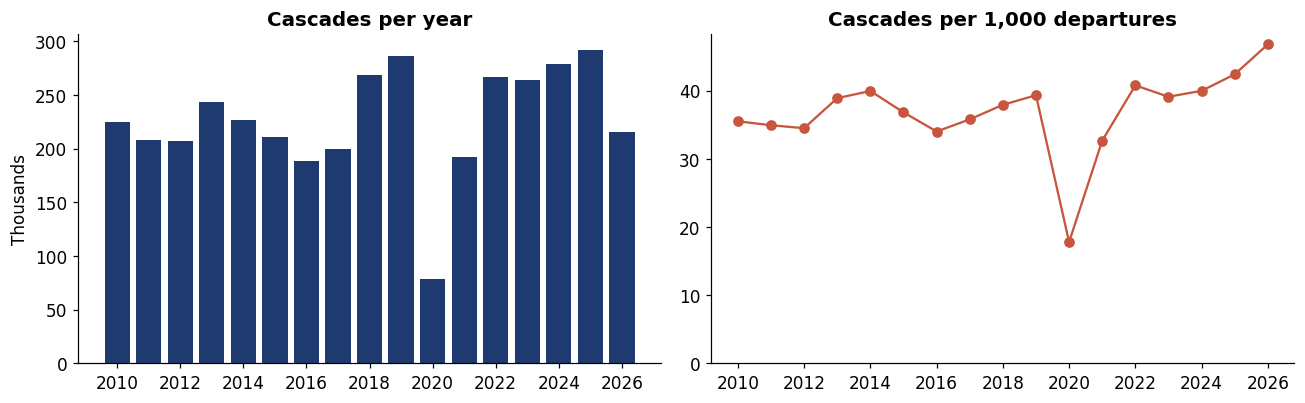

,Year,cascades,departures,per_1000
0,2010,224531,6321388,35.519256
1,2011,208062,5954903,34.939612
2,2012,207238,6005380,34.508724
3,2013,243576,6259310,38.914193
4,2014,226950,5678378,39.967399
5,2015,210455,5714008,36.831415
6,2016,188412,5538145,34.020778
7,2017,199747,5579410,35.800739
8,2018,268238,7070847,37.935766
9,2019,285945,7268232,39.341755


In [5]:
by_year = q(f"""
WITH c AS (SELECT Year, count(*) AS cascades FROM cascades GROUP BY 1),
     d AS (SELECT Year, count(*) AS departures FROM flight_chains GROUP BY 1)
SELECT Year, cascades, departures, 1000.0*cascades/departures AS per_1000 FROM c JOIN d USING (Year) ORDER BY Year""")
by_year.to_csv(TABLES/"cascades_by_year.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(by_year.Year, by_year.cascades/1000, color=NAVY); ax[0].set_title("Cascades per year"); ax[0].set_ylabel("Thousands")
ax[1].plot(by_year.Year, by_year.per_1000, marker="o", color=RED); ax[1].set_title("Cascades per 1,000 departures"); ax[1].set_ylim(bottom=0)
for a in ax: a.set_xticks(by_year.Year[::2])
fig.tight_layout(); save(fig, "04_cascades_by_year"); by_year

## 5 · Is it weather? Bad weather at the origin, by group
*Bad weather* = severe weather code, visibility under 5 km, or 2.5+ mm/h of precipitation at the origin in the scheduled departure hour. Only the top-50 airports have weather data.

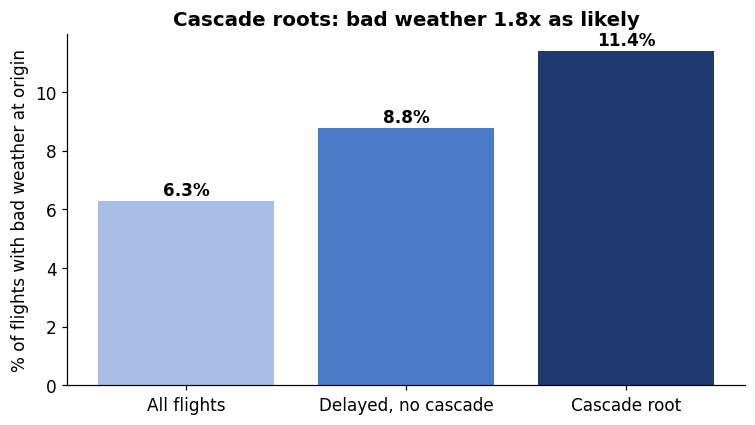

,grp,flights,pct_bad_weather
0,All flights,81562280,6.290205
1,"Delayed, no cascade",5774595,8.767160
2,Cascade root,3333918,11.389752


In [6]:
wx = q(f"""
WITH w AS (SELECT *, CASE WHEN coalesce(wx_bad, false) THEN CAST(1 AS DOUBLE) ELSE CAST(0 AS DOUBLE) END AS wxb FROM flights_features WHERE has_wx)
SELECT 'All flights' AS grp, count(*) AS flights, 100*avg(wxb) AS pct_bad_weather FROM w
UNION ALL
SELECT 'Delayed, no cascade', count(*), 100*avg(wxb) FROM w WHERE depth = 0 AND DepDelay >= 15 AND chain_len < 2
UNION ALL
SELECT 'Cascade root', count(*), 100*avg(wxb) FROM w WHERE depth = 0 AND DepDelay >= 15 AND chain_len >= 2""")
wx.to_csv(TABLES/"weather_split.csv", index=False)
base = wx.pct_bad_weather[0]; root = wx.pct_bad_weather[2]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(wx.grp, wx.pct_bad_weather, color=[LIGHT, BLUE, NAVY])
for b, v in zip(bars, wx.pct_bad_weather): ax.text(b.get_x()+b.get_width()/2, v+0.2, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_ylabel("% of flights with bad weather at origin"); ax.set_title(f"Cascade roots: bad weather {root/base:.1f}x as likely")
fig.tight_layout(); save(fig, "05_weather_split"); wx

## 6 · What explains delayed departures? Our classes vs. BTS's own cause minutes

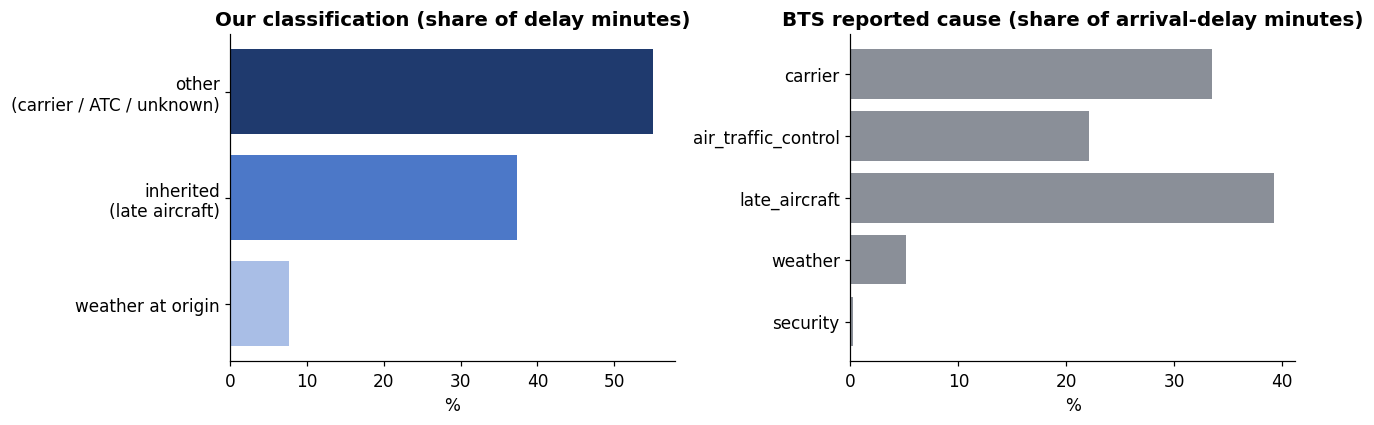

,delay_class,delayed_flights,delay_minutes,share_of_flights_pct,share_of_minutes_pct
0,other (carrier / ATC / unknown),10067650,548731800.0,63.286441,55.117935
1,inherited (late aircraft),4785397,371089867.0,30.081572,37.274507
2,weather at origin,1055021,75737757.0,6.631987,7.607558


In [7]:
cls = q(f"""
SELECT delay_class, count(*) AS delayed_flights, sum(DepDelay) AS delay_minutes
FROM flights_features WHERE has_wx AND DepDelay >= 15 GROUP BY 1 ORDER BY 2 DESC""")
cls["share_of_flights_pct"]  = 100*cls.delayed_flights/cls.delayed_flights.sum()
cls["share_of_minutes_pct"]  = 100*cls.delay_minutes/cls.delay_minutes.sum()
cls.to_csv(TABLES/"delay_classes.csv", index=False)

bts = q(f"""
SELECT sum(CarrierDelay) AS carrier, sum(NASDelay) AS air_traffic_control, sum(LateAircraftDelay) AS late_aircraft,
       sum(WeatherDelay) AS weather, sum(SecurityDelay) AS security
FROM flights_features WHERE has_wx AND ArrDelay >= 15""").iloc[0]
bts_pct = (100*bts/bts.sum()).round(1); bts_pct.to_csv(TABLES/"bts_cause_share.csv", header=["pct"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lab = cls.delay_class.str.replace(" (", "\n(", regex=False)
ax[0].barh(lab[::-1], cls.share_of_minutes_pct[::-1], color=[NAVY, BLUE, LIGHT][::-1][-len(cls):] if len(cls)<=3 else BLUE)
ax[0].set_title("Our classification (share of delay minutes)"); ax[0].set_xlabel("%")
ax[1].barh(bts_pct.index[::-1], bts_pct.values[::-1], color=GREY)
ax[1].set_title("BTS reported cause (share of arrival-delay minutes)"); ax[1].set_xlabel("%")
fig.tight_layout(); save(fig, "06_delay_causes"); cls

## Publish: copy charts and tables to Cloud Storage (cluster run only)

In [8]:
if RUN_ON == "gcp":
    for src, dest in [(FIG, FIG_DEST), (TABLES, TABLES_DEST)]:
        r = subprocess.run(["gcloud", "storage", "cp", "-r", f"{src}/*", dest + "/"], capture_output=True, text=True)
        print(("copied  " if r.returncode == 0 else "FAILED  ") + f"{src} -> {dest}", r.stderr[-300:] if r.returncode else "")
    print(subprocess.run(["gcloud", "storage", "ls", FIG_DEST], capture_output=True, text=True).stdout)
else:
    print("local run: charts are in", FIG)

copied  /tmp/figures -> gs://flightdelay-olivia-2026/gold/figures 
copied  /tmp/tables -> gs://flightdelay-olivia-2026/gold/tables 
gs://flightdelay-olivia-2026/gold/figures/01_top_airports.png
gs://flightdelay-olivia-2026/gold/figures/02_cascades_by_hour.png
gs://flightdelay-olivia-2026/gold/figures/03_airport_hour_heatmap.png
gs://flightdelay-olivia-2026/gold/figures/04_cascades_by_year.png
gs://flightdelay-olivia-2026/gold/figures/05_weather_split.png
gs://flightdelay-olivia-2026/gold/figures/06_delay_causes.png

